In [ ]:
%load_ext autoreload
%autoreload 2

import astropy.units as u
import matplotlib.pyplot as plt

import src.halo_dynamics as a
import src.subhalo_statistics as b

plt.style.use("src/nicefigures.mplstyle")
OUTPUT = "figures"

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


## A: Dynamical Analysis of a DM Halo

In [ ]:
data_path = "data/cutout_188106.hdf5"
pot_einasto, rho_einasto, r = a.build_Einasto(data_path)

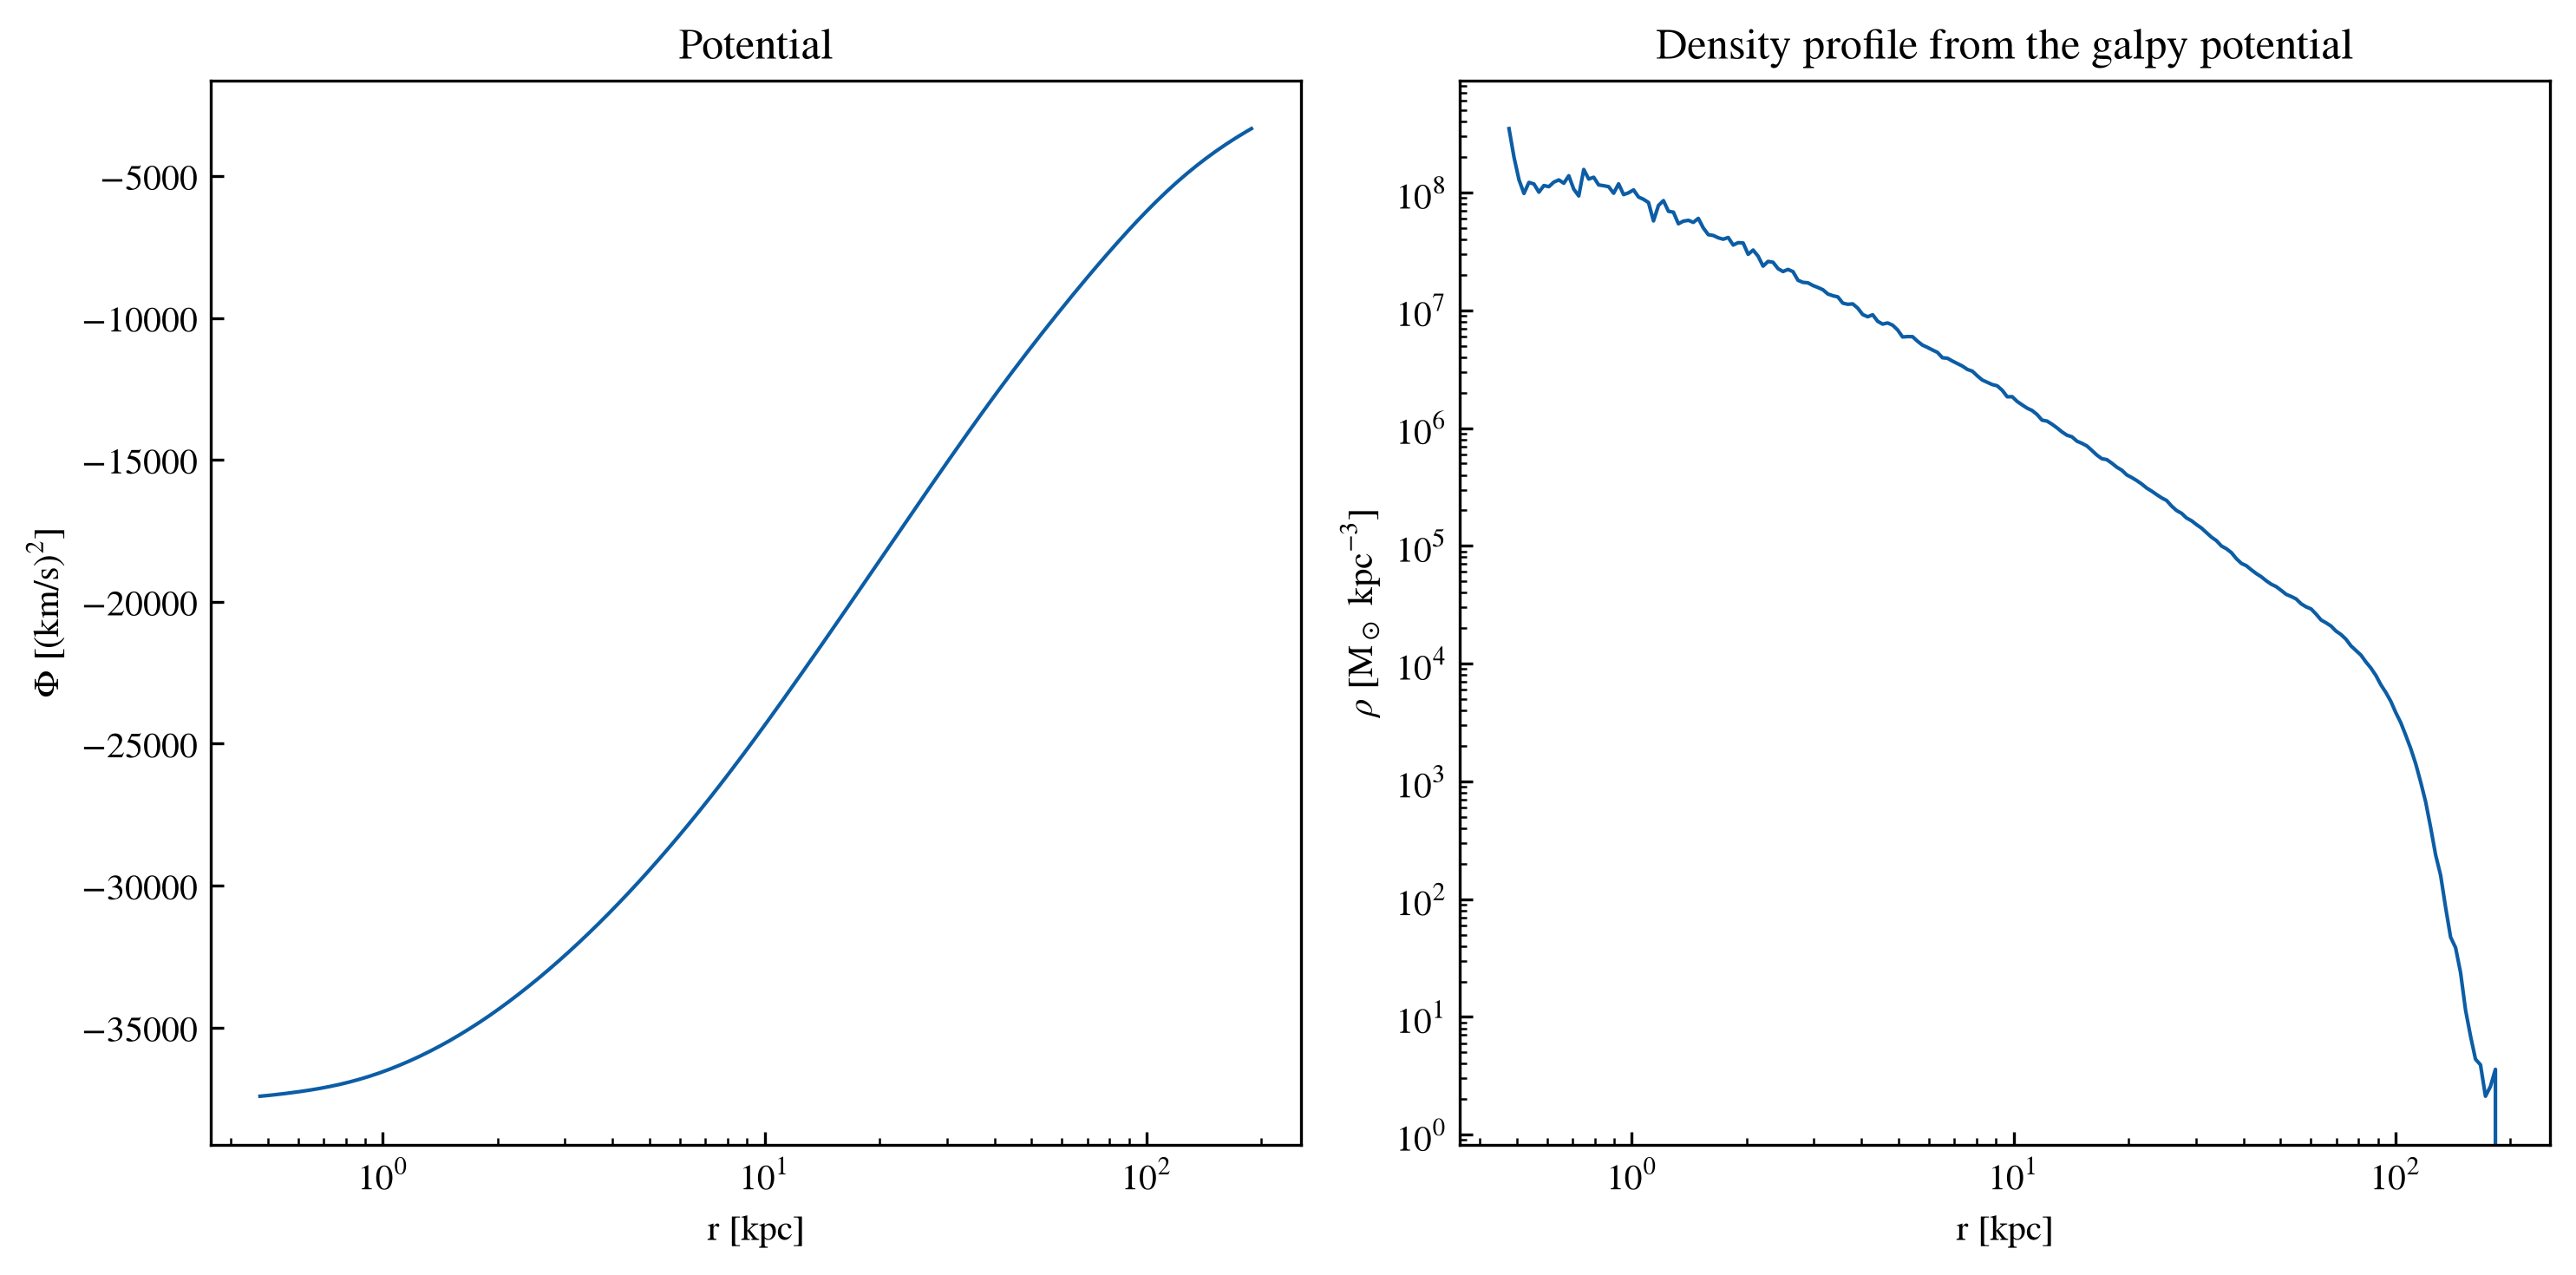

In [5]:
a.potential_plotter(data_path, plot=True, output=f"{OUTPUT}/halo_potential_density.png");

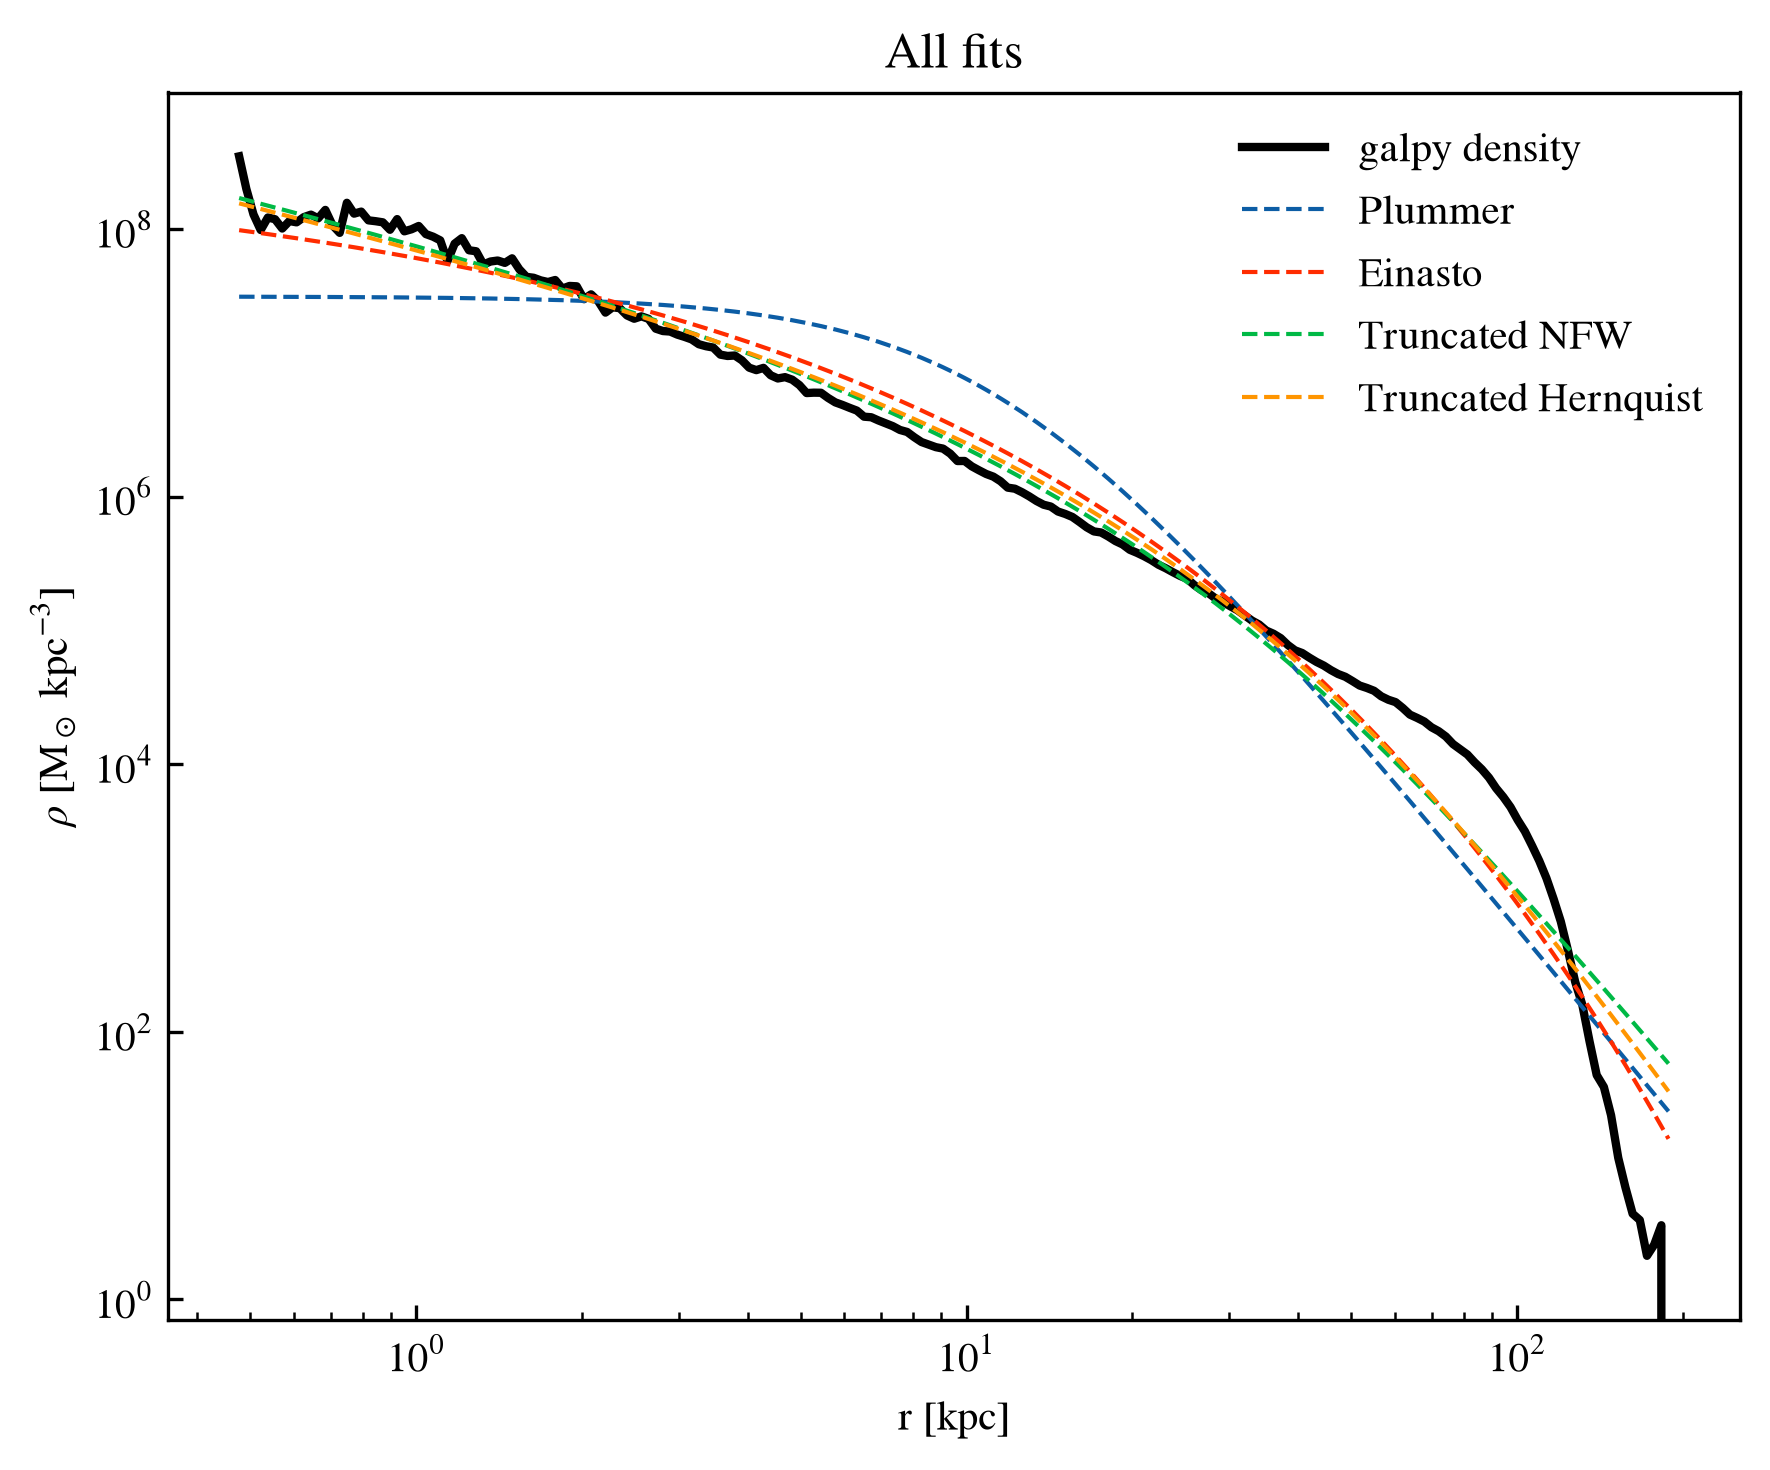

In [11]:
a.data_fitter(data_path, plot=True, output=f"{OUTPUT}/halo_density_fit.png");

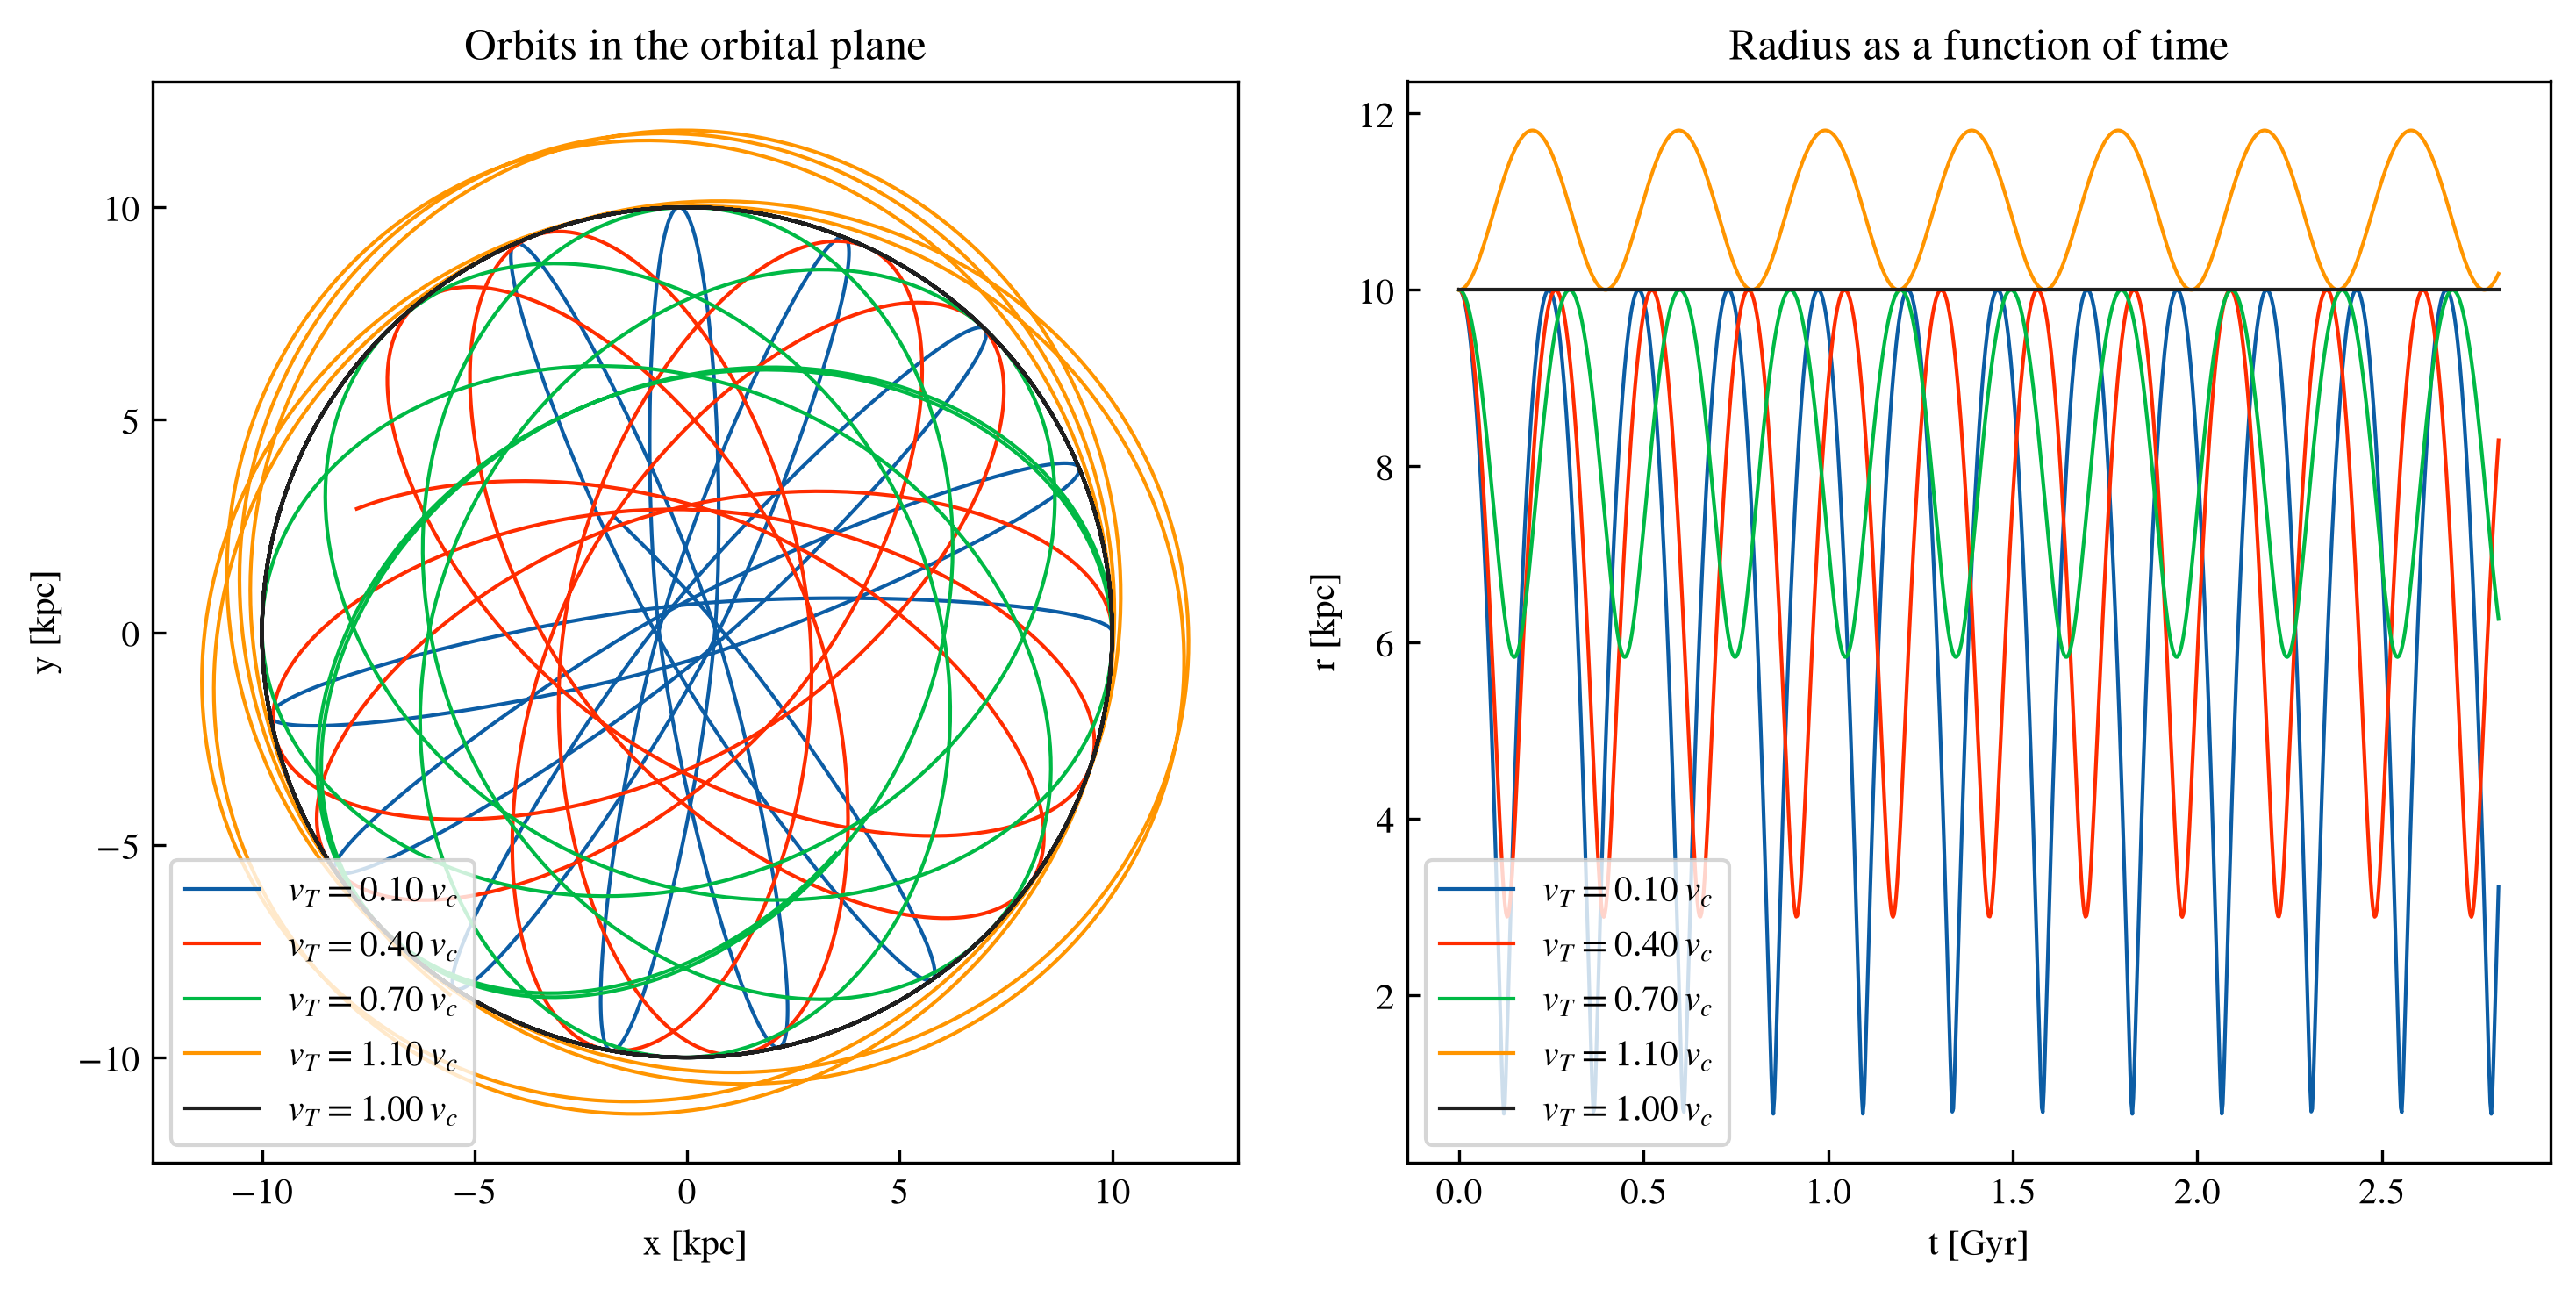

In [20]:
pot_einasto, rho_einasto, r = a.build_Einasto(data_path)
a.integrate_orbits(pot_einasto, r0=10 * u.kpc, f_vc=(0.1, 0.4, 0.7, 1.1, 1.0), plot=True, output=f"{OUTPUT}/dm_orbits_einasto.png");

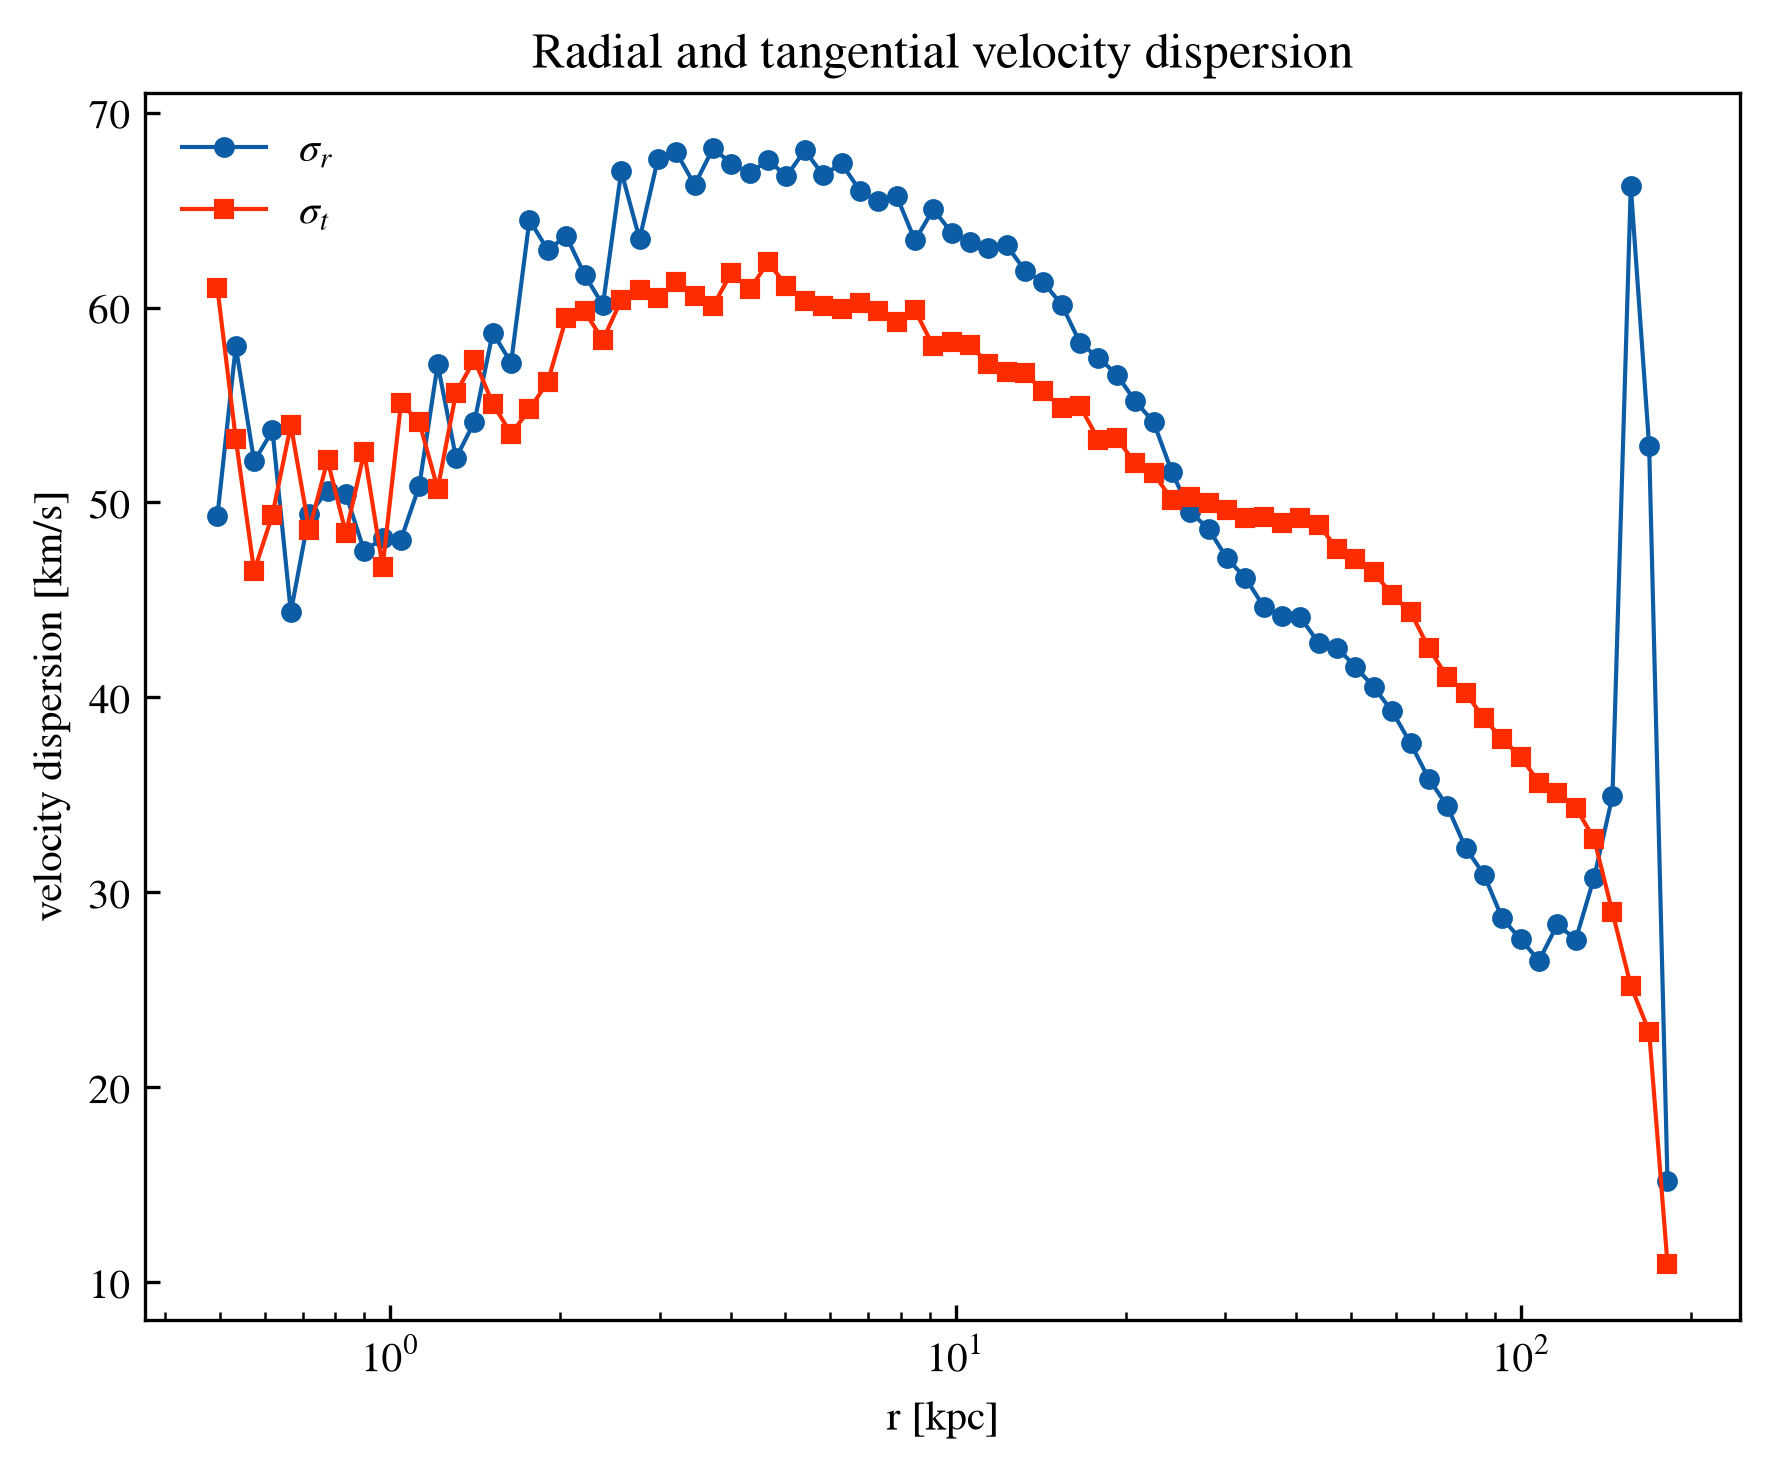

In [24]:
a.velocity_dispersions(data_path, n_bins=80, plot=True, output=f"{OUTPUT}/dm_dispersions.png");

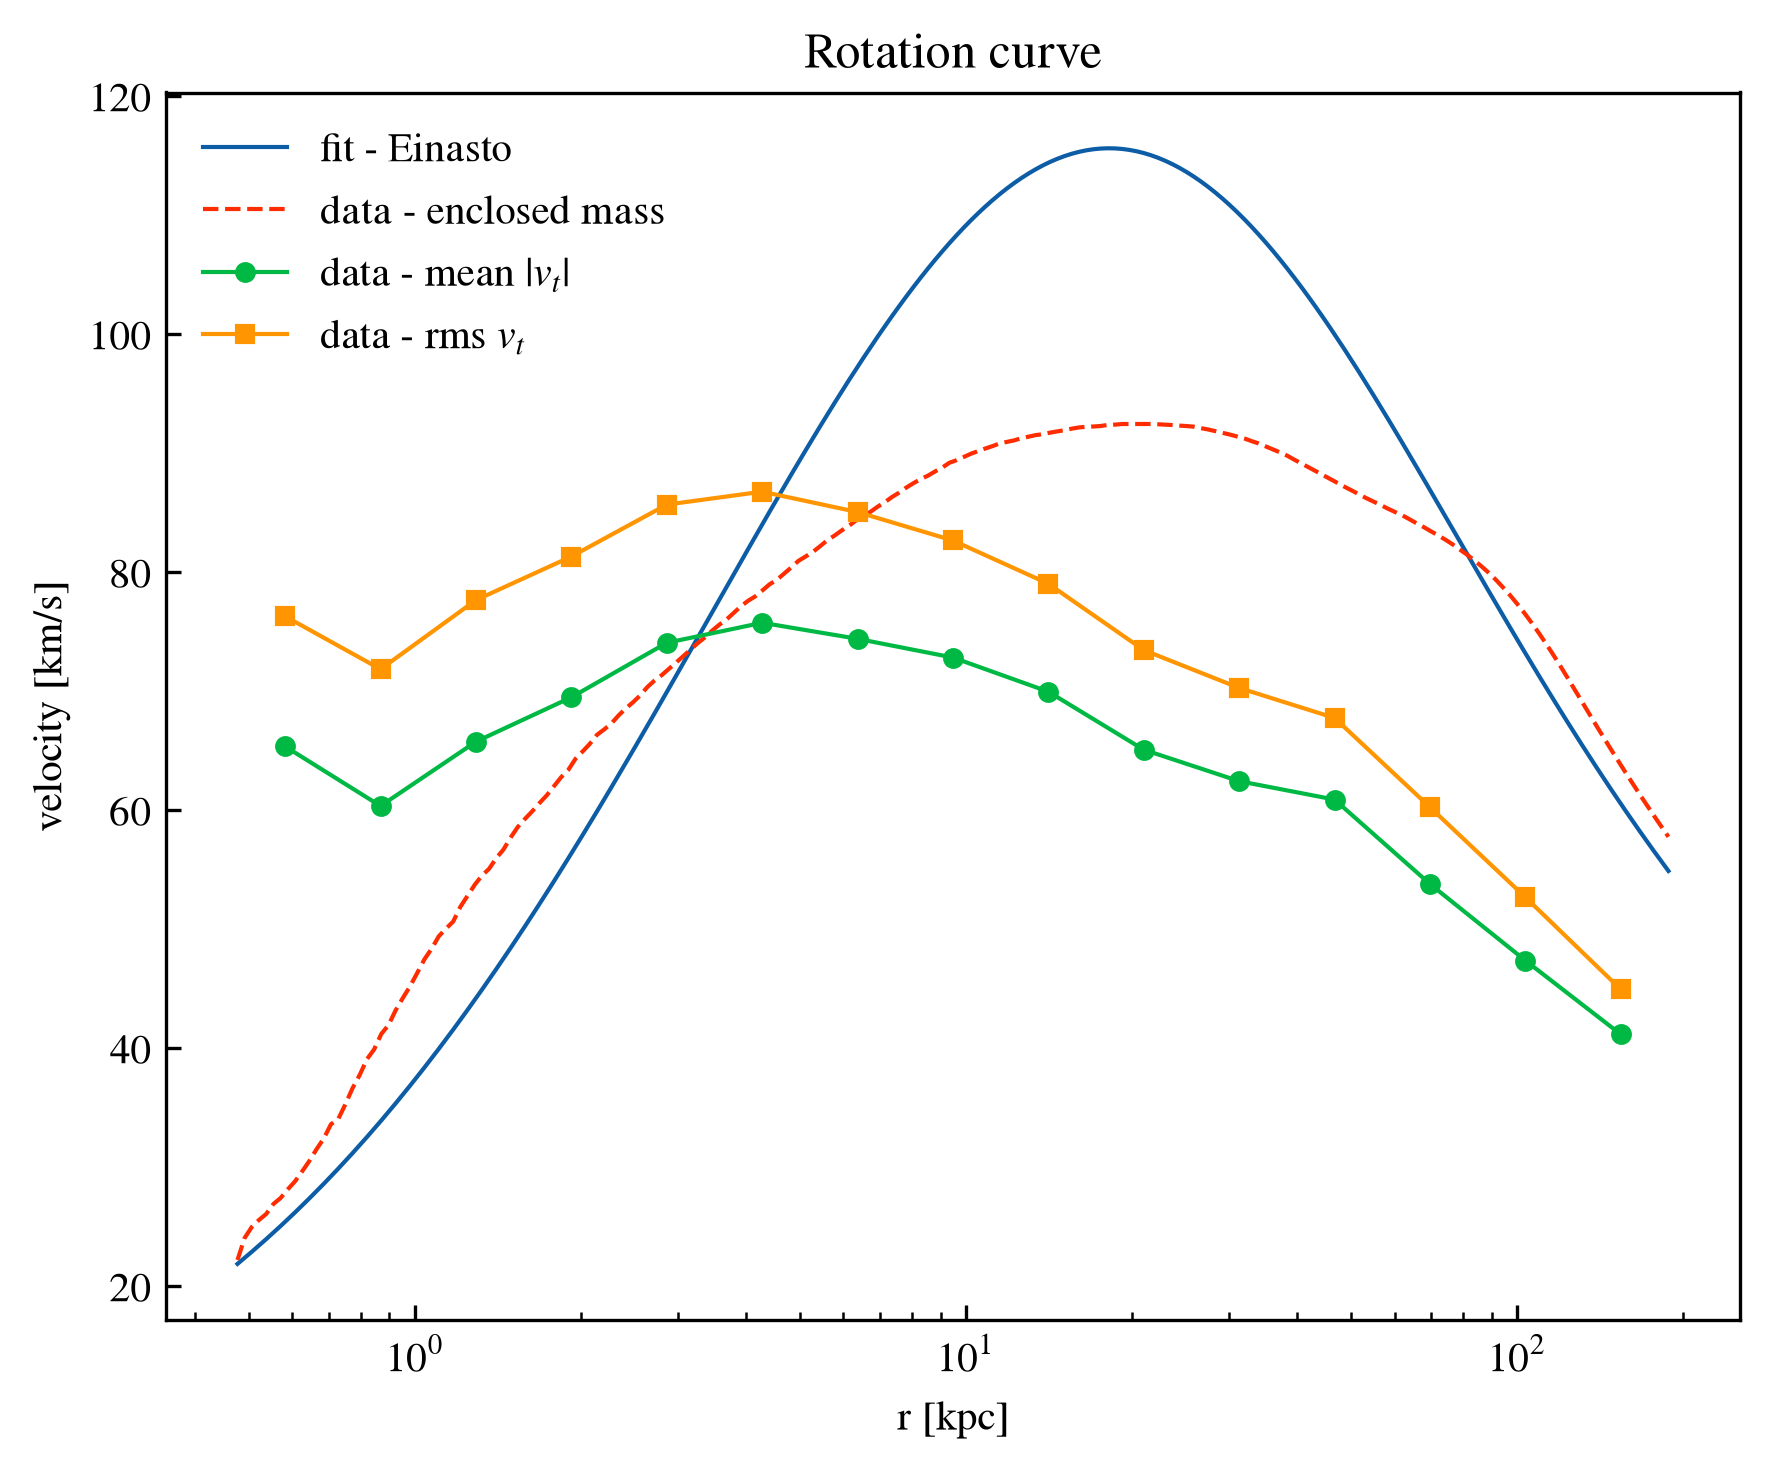

In [27]:
a.compare_rotation_curves(data_path, plot=True, output=f"{OUTPUT}/dm_circular_velocities.png");

## B: Large Scale Statistics

In [28]:
data_path = "data/TNG50-1-Dark_subhalosCat.hdf5"
min_mass = 0.0                  # minimum subhalo mass in Msun (0 = no cut)
max_correlation_halos = 40000   # subsample size for xi(r); 0 uses all subhalos
box_size, positions, masses = b.get_subhalo_data(data_path, min_mass=min_mass)
print(f"Box size: {box_size:.2f} cMpc, {len(masses)} subhalos after selection")

Box size: 51.67 cMpc, 6616159 subhalos after selection


### Mass Function

/home/lservaes/ugent/tana/project/src/subhalo_statistics.py:40: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  if min_mass > 0:

/home/lservaes/ugent/tana/project/src/subhalo_statistics.py:42: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  return box_size, positions[keep], masses[keep]

/home/lservaes/miniforge3/envs/tana/lib/python3.14/site-packages/IPython/core/events.py:101: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  func(*args, **kwargs)

/home/lservaes/miniforge3/envs/tana/lib/python3.14/site-packages/IPython/core/pylabtools.py:158: UserWarning: Creating legend with loc="best" can be slow with large amounts of data.
  fig.canvas.print_figure(bytes_io, **kw)



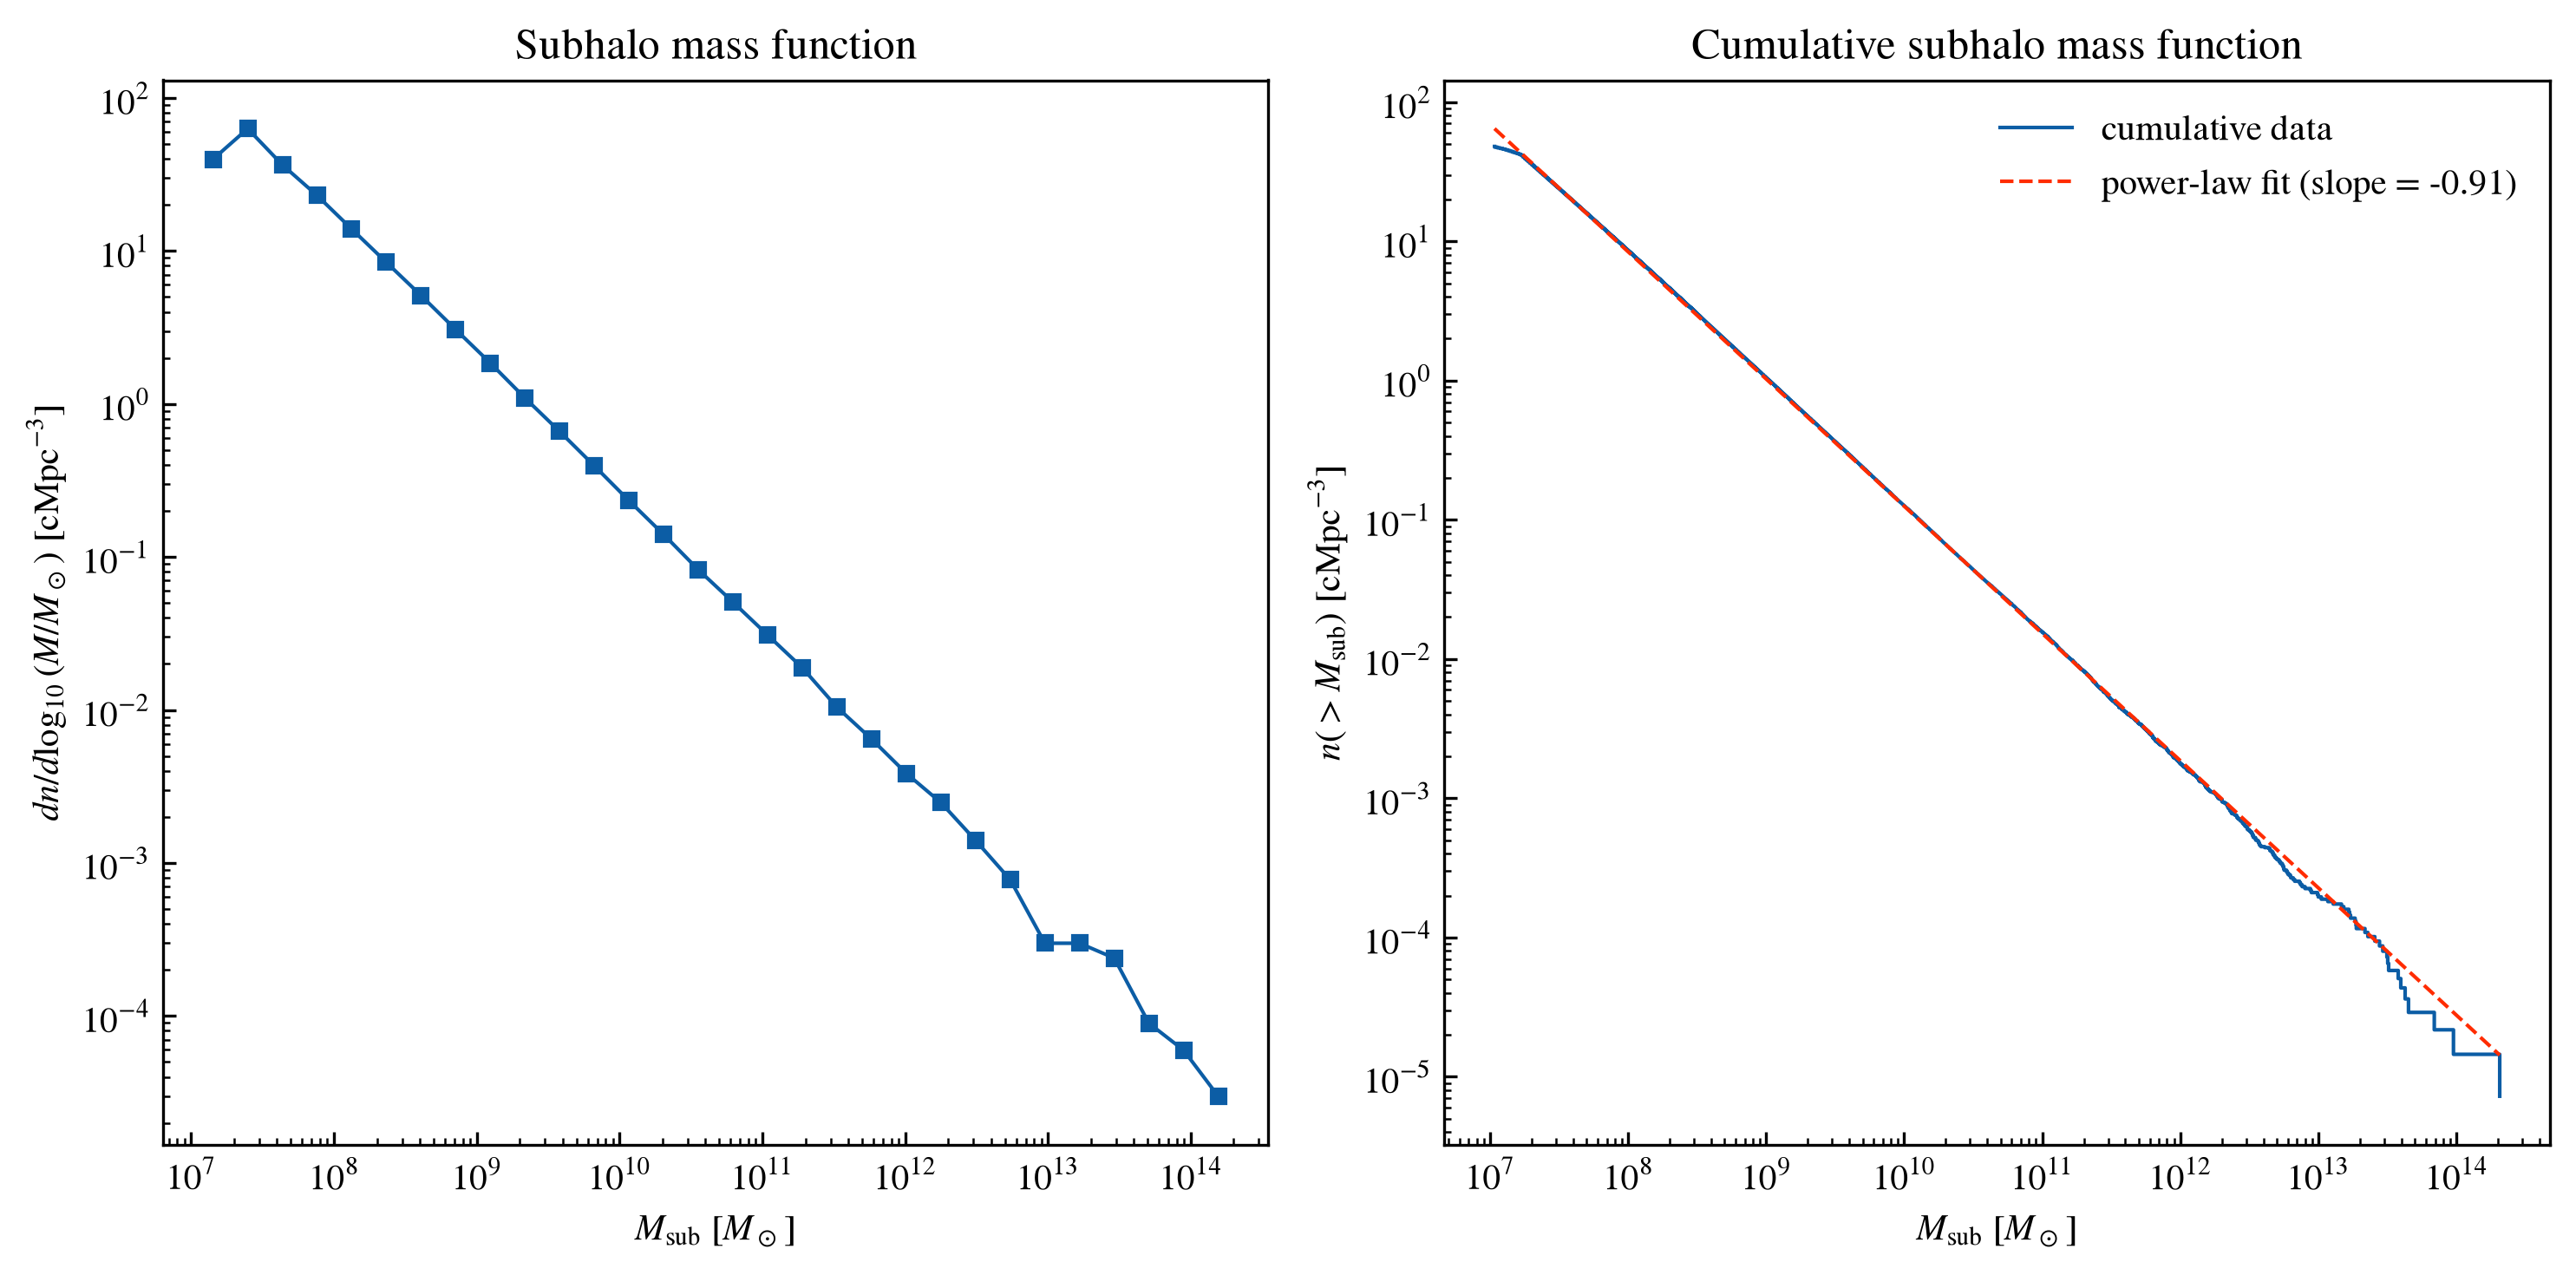

In [30]:
b.plot_mass_function(masses, box_size, output=f"{OUTPUT}/subhalo_mass_function.png");

Something something power law -1 corresponds to literature.

### Autocorrelation Function

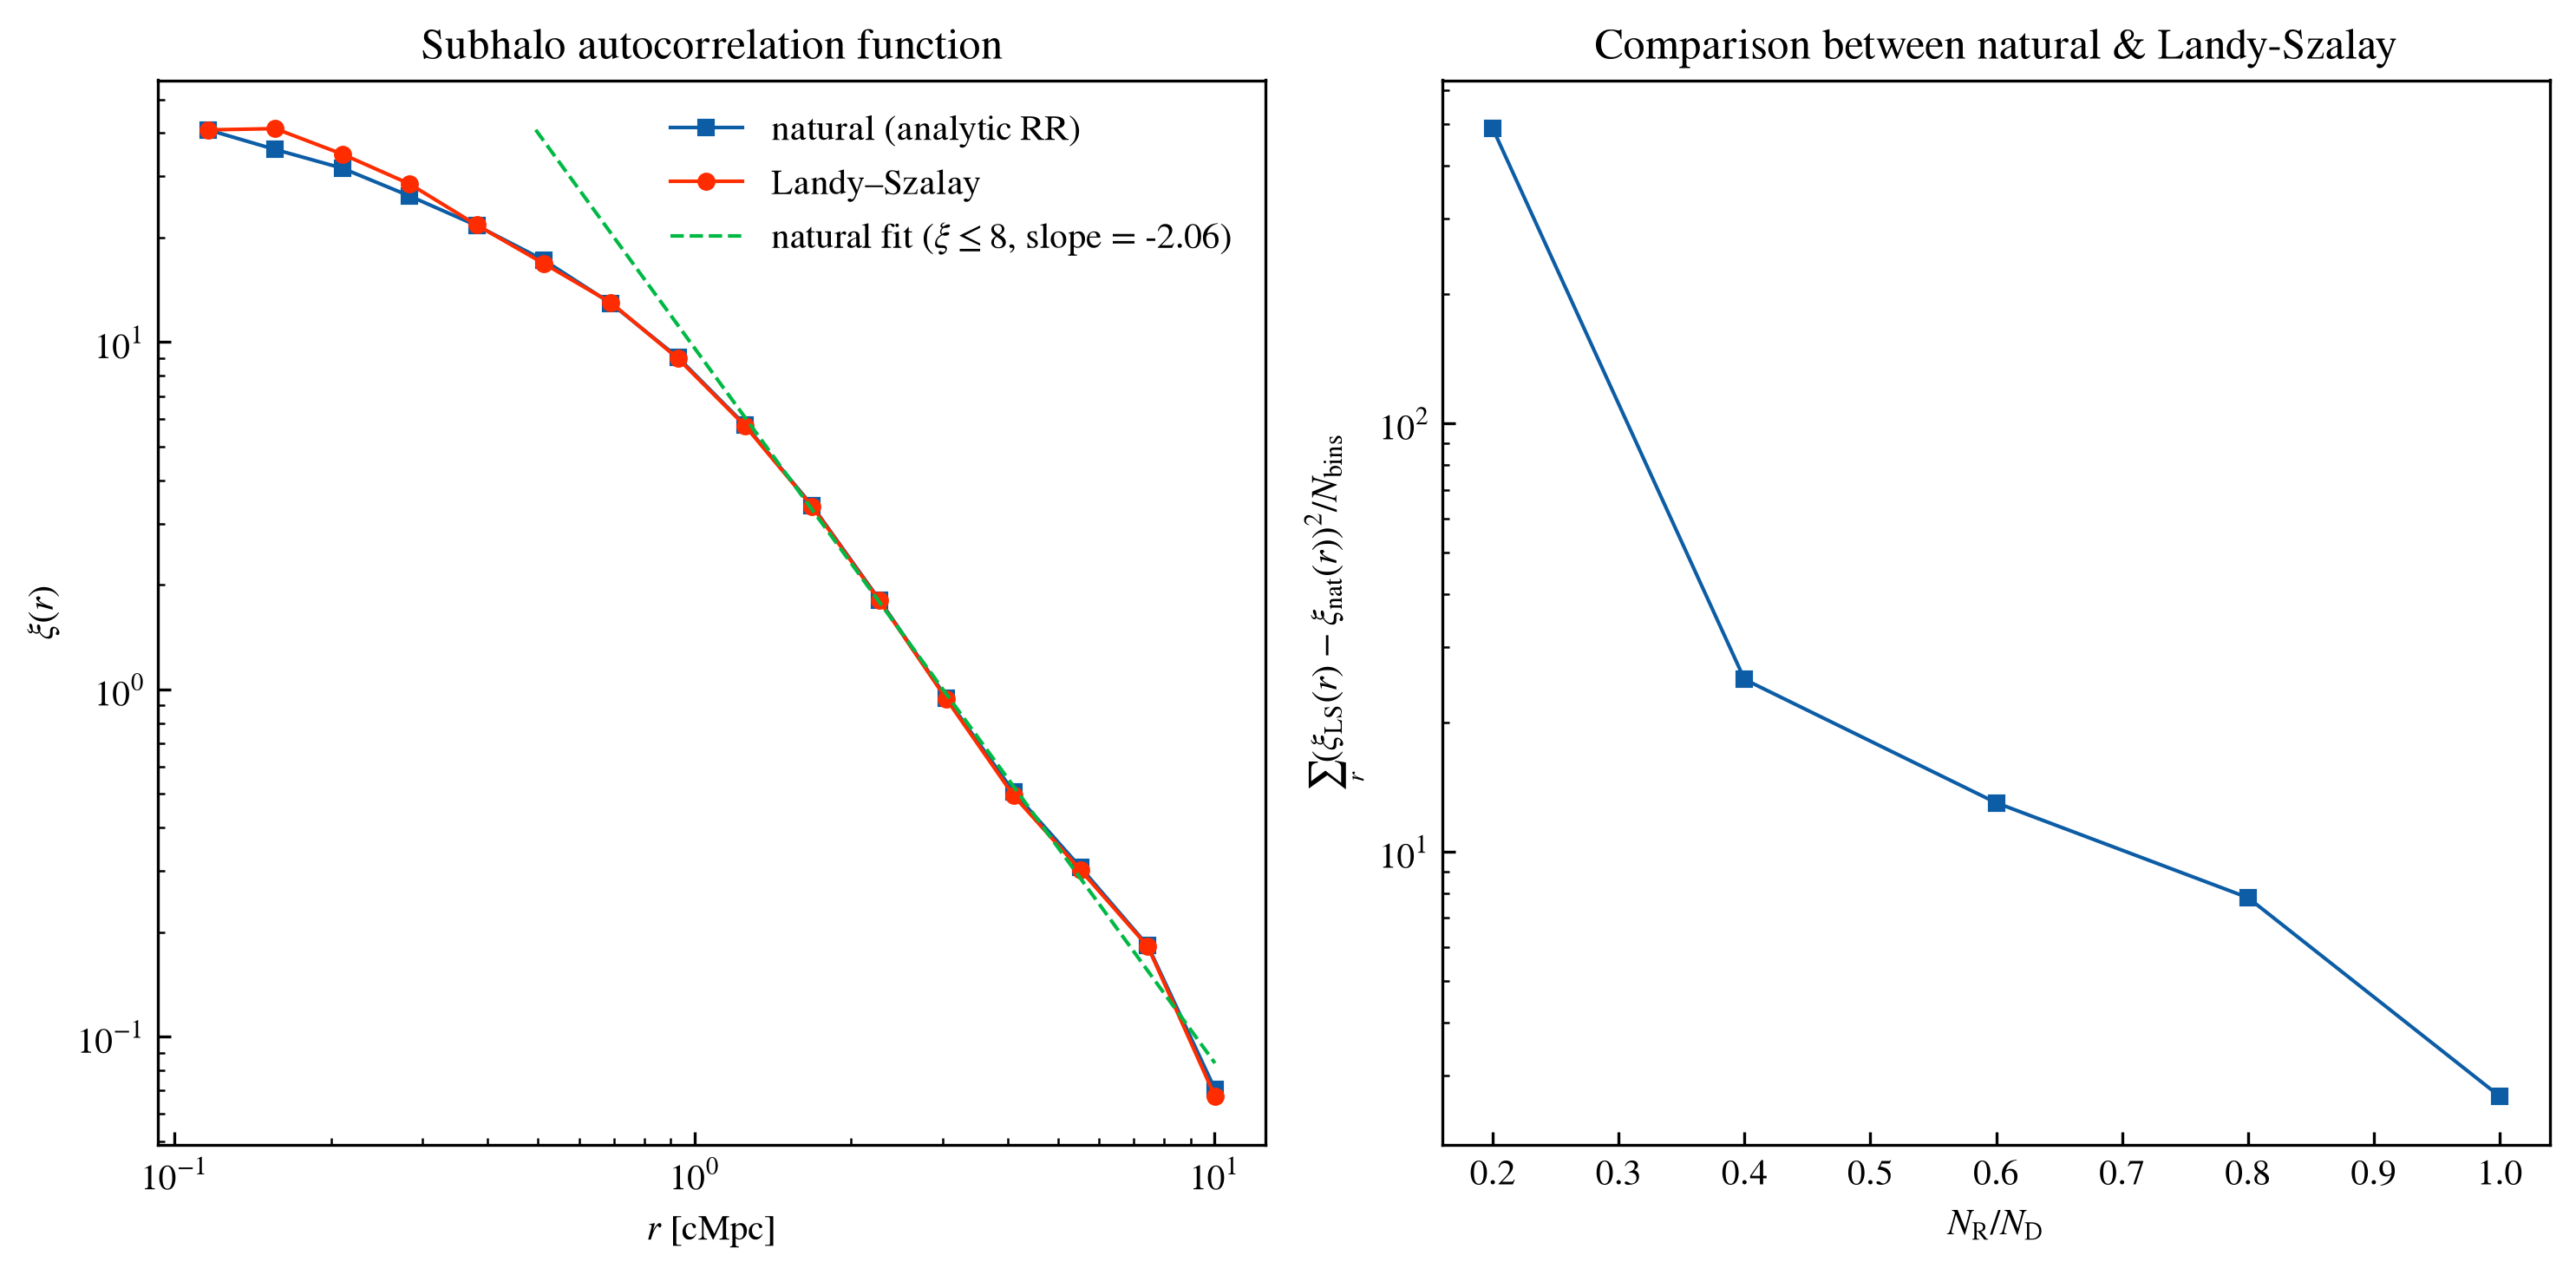

In [29]:
positions_sample = b.sample_positions(positions, max_halos=max_correlation_halos)
b.plot_correlation_function(positions_sample, box_size, output=f"{OUTPUT}/subhalo_correlation_function.png");

The natural and Landy-Szalay (LS) estimators for the autocorrelation function are defined as:

$$\chi_\mathrm{nat}(r) = \frac{\mathrm{DD}(r)}{\mathrm{RR}(r)} - 1 \quad\quad \chi_\mathrm{LS}(r) = \frac{\mathrm{DD}(r) - 2\mathrm{DR}(r)}{\mathrm{RR}(r)} + 1$$

where $\mathrm{AB}(r)$ is the number of pairs within a distance $[r/w, wr]$ (log bins) between catalogues $\mathrm{A}$ and $\mathrm{B}$ (normalized by the total number of pairs). In practice, $D$ is a uniformly selected subset of the TNG50 subhalo catalogue, and $R$ is randomly generated. An analytical expression for $\mathrm{RR}(r)$ can be obtained by considering spherical shells between two radii $r/w, wr$. Then, the number of particles within a shell is given by the density x volume fraction of that shell, and the number of pairs is:

$$\mathrm{RR}(r) = \frac{N(N - 1)}{2} \frac{4\pi r^3}{3L^3}(w^3 - \frac{1}{w^3})$$

Since TNG50 is a periodic cosmological volume, this is valid for $r < L/2$ (and indeed $\xi(r)$ only makes sense for this range). Furthermore, $\mathrm{DR}(r) = \mathrm{RR}(r)$ and the LS estimator is reduced to the natural one.

The natural estimator was calculated using the analytical expression, while for the LS estimator a random catalogue was built. At small distances, there is a discrepancy between the two, since the pair count for the random catalogue at that distance is low. To show that this is noise of random origin, the difference between natural and LS is plotted (right) for increasing size of the random catalogue. Indeed, one observes a systematic decrease.